# Chapter 4. 파인튜닝 — 실제 데이터로 안전모 감지 모델 만들기

## 4.1 파인튜닝이란?

**파인튜닝(Fine-Tuning)**은 이미 대규모 데이터로 학습된 모델을 **나의 데이터셋으로 추가 학습**하는 방법입니다.

```
일반 모델 (COCO 80종 학습)
     ↓  파인튜닝
나만의 모델 (안전모 감지 전문가)
```

YOLO26은 COCO 데이터셋의 80가지 일상 객체를 탐지합니다.  
`person`, `car`, `bottle` 등은 탐지하지만,  
**안전모(hardhat)**, **공장 불량품**, **특수 의료 장비** 등 COCO에 없는 객체는 탐지할 수 없습니다.

### 파인튜닝 vs 처음부터 학습

| 방식 | 시작점 | 데이터 필요량 | 학습 시간 | 성능 |
|------|--------|--------------|----------|------|
| **파인튜닝** | 사전 학습 가중치 재사용 | 수백~수천 장 | 짧음 | 높음 |
| 처음부터 학습 | 무작위 가중치 | 수십만 장 이상 | 매우 길음 | 동일 조건에서 낮음 |

> 💡 실전에서는 거의 항상 **파인튜닝**을 사용합니다.

---

## 4.2 실습 시나리오 — 공사장 안전모 감지

### 문제 상황

공사 현장에서 **안전모를 착용하지 않은 작업자**를 실시간으로 감지하면  
사고를 예방하고 안전 감독 비용을 줄일 수 있습니다.  
산업안전보건법상 안전모 미착용은 즉각적인 조치 대상입니다.

### 기본 YOLO26 모델의 한계

기본 모델은 COCO 80종만 탐지합니다. `person`은 감지하지만,  
`hardhat`(안전모 착용)이나 `head`(안전모 미착용 머리)는 클래스 자체가 없습니다.

```
기본 모델 → person ✅ / hardhat ❌ / head(미착용) ❌
파인튜닝 → Hardhat ✅ / Head(미착용) ✅ / Person ✅
```

---

## 4.3 Kaggle에서 데이터셋 준비하기

### Kaggle이란?

[Kaggle](https://kaggle.com)은 세계 최대 데이터 과학 플랫폼으로, **수십만 개의 공개 데이터셋**을 무료로 제공합니다.  
로그인만 하면 Python 코드로 바로 다운로드할 수 있습니다.

### 실습 데이터셋: Safety Helmet Detection

| 항목 | 내용 |
|------|------|
| 데이터셋 | Safety Helmet Detection (by andrewmvd) |
| 출처 | Kaggle 공개 데이터셋 |
| 클래스 | `helmet`(안전모 착용) / `head`(안전모 미착용) / `person`(사람) |
| 이미지 수 | 약 5,000장 |
| 어노테이션 형식 | Pascal VOC (XML) |
| 용도 | 공사 현장 안전 모니터링 |

> 💡 Kaggle 데이터셋은 Pascal VOC 형식인 경우가 많습니다. YOLO 학습에 앞서 변환 과정이 필요합니다.


- matplotlib 설정

In [1]:
%matplotlib inline

### 데이터셋 다운로드

In [2]:
!kaggle auth login

Your browser has been opened to visit:
  https://www.kaggle.com/api/v1/oauth2/authorize?response_type=code&client_id=kagglesdk&redirect_uri=http%3A%2F%2Flocalhost%3A8645&scope=resources.admin%3A%2A&state=7b2e90f7-35ab-44bb-aa93-e1b000fa267f&code_challenge=csfydjbanTgmv7t95bDY9HiISk3Z-zdNf6IRQEOTKZ8%3D&code_challenge_method=S256&response_mode=query



You are now logged in as [jsamuel1648619]



127.0.0.1 - - [29/Oct/2026 15:01:29] "GET /?code=CfDJ8FwkkMkekkBCtzoFDl4Vj7gzqIkD6CvdJ_QcxIryV9us-7sla_yLi9JRndHiu7-PaEg7Y15kgTG7KL2ZYzmSKmhTkmpqo9bdzkcayTEKYUcT0WZwBlMptnpl9PIP3INEfcb6CL2BjePppJ52Btccfkf4C8C4OUGigdVKKrZbi8c_F7PPugoI7Yoq67ns6WeDKxKdlPbgh5USP6UWcx0WSQVJJcnQhW7nI_yijZomSwZr_kfG5qKufu4zhYGXTjnC1pwvdKYQTml1ZchXEIyRybMmmcH5dB419D5D1dNc_OPMFdye95Rm1PAUuBRnTno&state=7b2e90f7-35ab-44bb-aa93-e1b000fa267f HTTP/1.1" 200 -


In [3]:
from dotenv import load_dotenv
load_dotenv()

import kaggle

DATASET_RAW = "./hard-hat-detection-raw"

kaggle.api.dataset_download_files(
    "andrewmvd/hard-hat-detection",
    path=DATASET_RAW,
    unzip=True
)
print("다운로드 완료:", DATASET_RAW)

Dataset URL: https://www.kaggle.com/datasets/andrewmvd/hard-hat-detection
다운로드 완료: ./hard-hat-detection-raw


### Pascal VOC → YOLO 형식 변환

Kaggle에서 받은 데이터는 Pascal VOC 형식(XML)이라 YOLO 학습에 바로 쓸 수 없습니다.  
바운딩 박스 좌표를 YOLO 형식(정규화된 cx, cy, w, h)으로 변환하고, train/valid를 80/20으로 분할합니다.

In [4]:
import xml.etree.ElementTree as ET
from pathlib import Path
import random
import yaml
import shutil

CLASSES = ['helmet', 'head', 'person']
SRC_IMAGES = Path(DATASET_RAW) / "images"
SRC_ANNOTS = Path(DATASET_RAW) / "annotations"
DATASET_PATH = "./hard-hat-detection-yolo"

def voc_to_yolo_lines(xml_path):
    root = ET.parse(xml_path).getroot()
    size = root.find('size')
    img_w = float(size.find('width').text)
    img_h = float(size.find('height').text)
    lines = []
    for obj in root.findall('object'):
        name = obj.find('name').text
        if name not in CLASSES:
            continue
        cls_id = CLASSES.index(name)
        bb = obj.find('bndbox')
        xmin = float(bb.find('xmin').text)
        ymin = float(bb.find('ymin').text)
        xmax = float(bb.find('xmax').text)
        ymax = float(bb.find('ymax').text)
        cx = (xmin + xmax) / 2 / img_w
        cy = (ymin + ymax) / 2 / img_h
        w  = (xmax - xmin) / img_w
        h  = (ymax - ymin) / img_h
        lines.append(f"{cls_id} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}")
    return lines

xml_files = sorted(SRC_ANNOTS.glob("*.xml"))
random.seed(42)
random.shuffle(xml_files)
split_idx = int(len(xml_files) * 0.8)
splits = {"train": xml_files[:split_idx], "valid": xml_files[split_idx:]}

for split_name, files in splits.items():
    img_dir = Path(DATASET_PATH) / split_name / "images"
    lbl_dir = Path(DATASET_PATH) / split_name / "labels"
    img_dir.mkdir(parents=True, exist_ok=True)
    lbl_dir.mkdir(parents=True, exist_ok=True)
    for xml_path in files:
        stem = xml_path.stem
        img_src = next((SRC_IMAGES / f"{stem}{ext}" for ext in (".png", ".jpg", ".jpeg")
                        if (SRC_IMAGES / f"{stem}{ext}").exists()), None)
        if img_src is None:
            continue
        shutil.copy(img_src, img_dir / img_src.name)
        lines = voc_to_yolo_lines(xml_path)
        (lbl_dir / f"{stem}.txt").write_text("\n".join(lines))

data_yaml = {"train": "train/images", "val": "valid/images",
             "nc": len(CLASSES), "names": CLASSES}
with open(f"{DATASET_PATH}/data.yaml", "w") as f:
    yaml.dump(data_yaml, f, allow_unicode=True)

print(f"변환 완료: {DATASET_PATH}")
print(f"학습 {len(splits['train'])}장 / 검증 {len(splits['valid'])}장")

변환 완료: ./hard-hat-detection-yolo
학습 4000장 / 검증 1000장


---

## 4.4 YOLO 데이터셋 형식

### 폴더 구조

```
hard-hat-detection-yolo/
├── train/
│   ├── images/       ← 학습용 이미지 (.jpg)
│   └── labels/       ← 학습용 어노테이션 (.txt)
├── valid/
│   ├── images/       ← 검증용 이미지
│   └── labels/       ← 검증용 어노테이션
└── data.yaml         ← 데이터셋 설정 파일
```

### 어노테이션 파일 형식 (.txt)

이미지 1장 = 텍스트 파일 1개. 객체 1개 = 1줄.

```
클래스ID  cx  cy  w  h
```

- `cx`, `cy`: 바운딩 박스 **중심점** 좌표 (0~1 정규화)
- `w`, `h`: 바운딩 박스 **너비/높이** (0~1 정규화)

### data.yaml 예시

```yaml
train: train/images
val:   valid/images

nc: 3
names: ['Hardhat', 'Head', 'Person']
```

---

## 4.5 파인튜닝 실행

### 주요 파라미터

| 파라미터 | 설명 | CPU 권장 | GPU 권장 (16GiB) |
|---------|------|---------|----------|
| `device` | 학습장치 | "cpu" | "cuda:0" |
| `epochs` | 학습 반복 횟수 | 10 | 30 |
| `batch` | 배치 크기 | 4 | 32 |
| `imgsz` | 입력 이미지 크기 | 640 | 640 |
| `fraction` | 데이터 사용 비율 | 0.1 | 1.0 |
| `patience` | Early Stopping 기준 | 10 | 20 |
| `cache` | 캐시 사용 | False | "ram" |
| `amp` | amp 사용 | False | True |

In [ ]:
from ultralytics import YOLO
from pathlib import Path

model = YOLO("yolo26n.pt")
data_yaml = str(Path(DATASET_PATH) / "data.yaml")

results = model.train(
    data=data_yaml,
    epochs=30,
    imgsz=640,
    batch=16,  # 8GiB 16 / 16GiB 32 권장
    fraction=1.0,
    device="cuda:0",
    project="finetune",
    name="hardhat_detection",
    patience=10,
    verbose=False,
    cache="ram",
    amp=True,
    workers=4,  # 8GiB 4, 16GiB 8 권장
)

SAVE_DIR = results.save_dir
print("학습 완료! 결과 저장 경로:", SAVE_DIR)

Ultralytics 8.4.192  Python-3.11.9 torch-2.9.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16311MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=hard-hat-detection-yolo\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=hardhat_detection-2, nbs=64, nms=None, ops

---

## 4.6 학습 결과 분석

| 파일 | 설명 |
|------|------|
| `weights/best.pt` | 검증 성능이 가장 좋았던 시점의 모델 |
| `weights/last.pt` | 마지막 epoch의 모델 |
| `results.csv` | epoch별 손실값, mAP 등 수치 기록 |
| `results.png` | 학습 곡선 그래프 |
| `confusion_matrix.png` | 혼동 행렬 |
| `BoxPR_curve.png` | Precision-Recall 곡선 |

---

## 4.7 주요 지표 — mAP 이해하기

| 지표 | 기준 | 의미 |
|------|------|------|
| **mAP50** | IoU ≥ 0.5 | 50% 이상 겹치면 정답으로 인정 — 관대한 기준 |
| **mAP50-95** | IoU 0.5~0.95 평균 | 더 엄격한 기준, 실제 성능을 잘 반영 |

| mAP50 | 평가 |
|-------|------|
| > 0.85 | 우수 |
| 0.70~0.85 | 실용적 |
| < 0.70 | 추가 데이터/학습 필요 |

> 💡 `fraction=0.1`, `epochs=10`의 빠른 실습에서는 mAP가 낮게 나옵니다.  
> 전체 데이터 + 충분한 epoch 학습 시 mAP50 > 0.85를 기대할 수 있습니다.

---

## 4.8 파인튜닝 모델로 추론

In [5]:
%matplotlib inline

파인튜닝 모델 클래스: {0: 'helmet', 1: 'head', 2: 'person'}


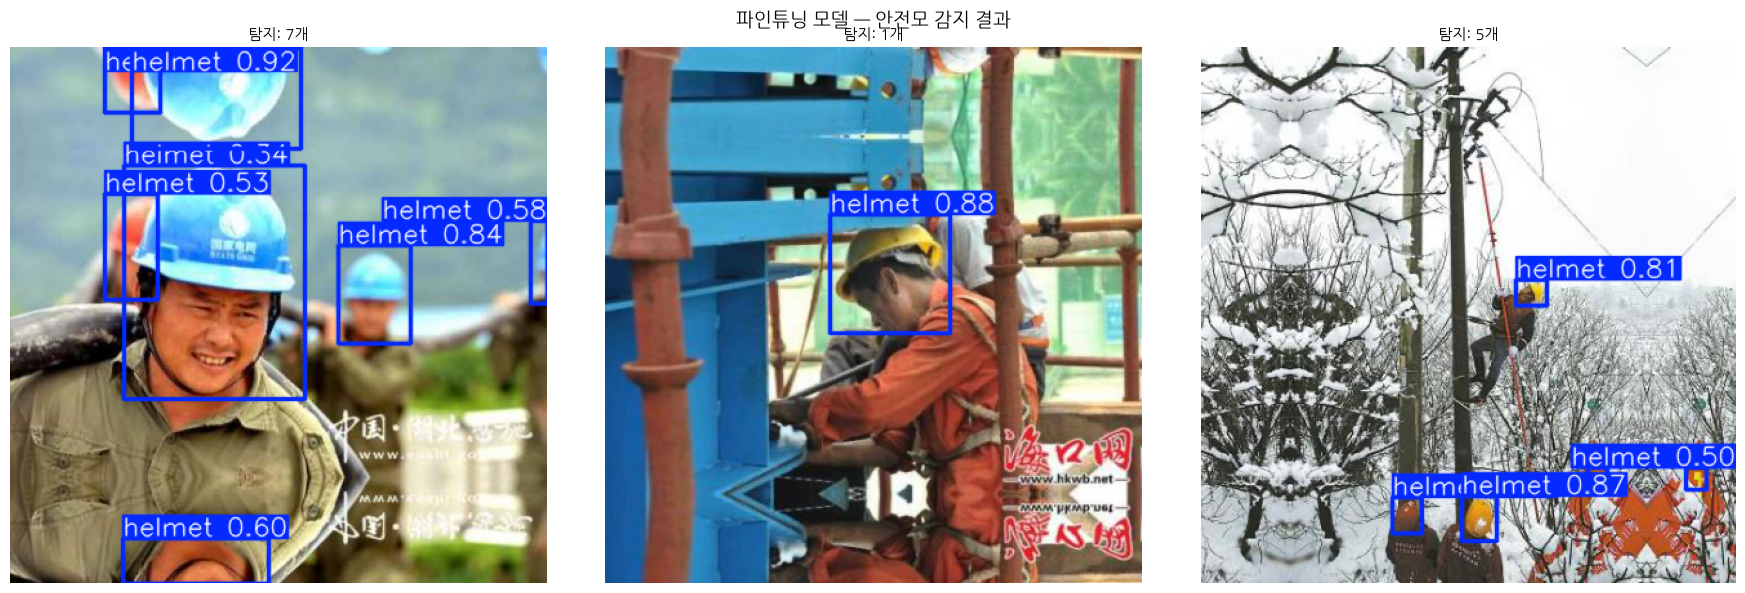

In [7]:
import random
from ultralytics import YOLO
from pathlib import Path
import matplotlib.pyplot as plt
import koreanize_matplotlib

model_ft = YOLO(str(Path(SAVE_DIR) / "weights" / "best.pt"))
print("파인튜닝 모델 클래스:", model_ft.names)

val_dir = Path(DATASET_PATH) / "valid" / "images"
val_images = sorted(list(val_dir.glob("*.jpg")) + list(val_dir.glob("*.png")))
sample_imgs = random.sample(val_images, min(3, len(val_images)))

fig, axes = plt.subplots(1, len(sample_imgs), figsize=(18, 6))
for ax, img_path in zip(axes, sample_imgs):
    result = model_ft(str(img_path), verbose=False)[0]
    ax.imshow(result.plot()[..., ::-1])
    ax.set_title(f"탐지: {len(result.boxes)}개", fontsize=11)
    ax.axis("off")

plt.suptitle("파인튜닝 모델 — 안전모 감지 결과", fontsize=14)
plt.tight_layout()
plt.show()

---

## 4.9 기본 모델 vs 파인튜닝 모델 비교

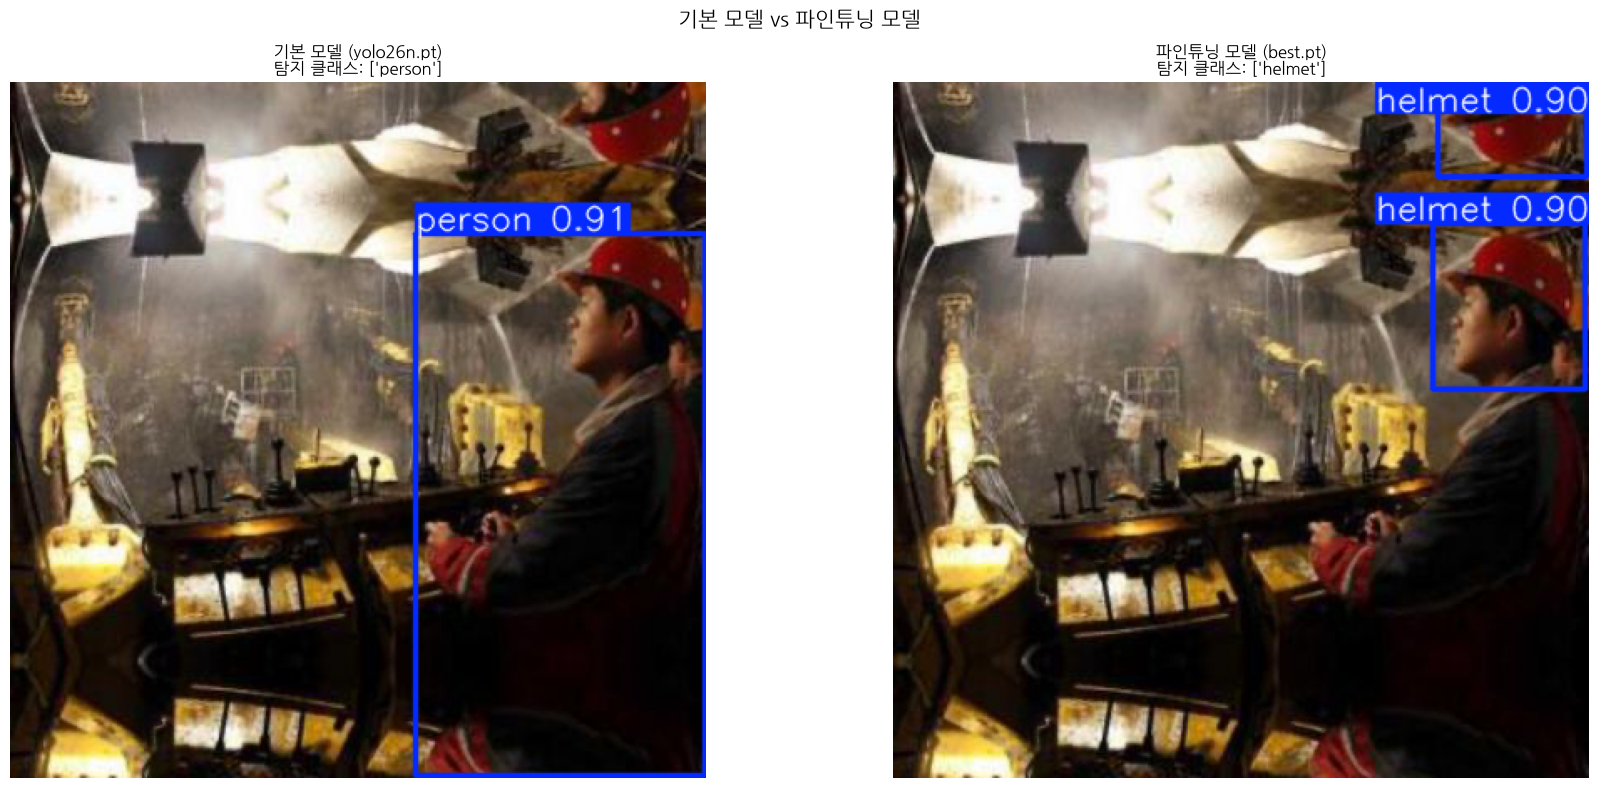

In [8]:
import random
from ultralytics import YOLO
from pathlib import Path
import matplotlib.pyplot as plt
import koreanize_matplotlib

val_dir = Path(DATASET_PATH) / "valid" / "images"
val_images = sorted(list(val_dir.glob("*.jpg")) + list(val_dir.glob("*.png")))
test_img = str(random.choice(val_images))

model_base = YOLO("yolo26n.pt")
model_ft   = YOLO(str(Path(SAVE_DIR) / "weights" / "best.pt"))

result_base = model_base(test_img, verbose=False)[0]
result_ft   = model_ft(test_img, verbose=False)[0]

base_classes = sorted(set(model_base.names[int(b.cls)] for b in result_base.boxes))
ft_classes   = sorted(set(model_ft.names[int(b.cls)]   for b in result_ft.boxes))

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

axes[0].imshow(result_base.plot()[..., ::-1])
axes[0].set_title(f"기본 모델 (yolo26n.pt)\n탐지 클래스: {base_classes}", fontsize=12)
axes[0].axis("off")

axes[1].imshow(result_ft.plot()[..., ::-1])
axes[1].set_title(f"파인튜닝 모델 (best.pt)\n탐지 클래스: {ft_classes}", fontsize=12)
axes[1].axis("off")

plt.suptitle("기본 모델 vs 파인튜닝 모델", fontsize=15)
plt.tight_layout()
plt.show()

---

## 4.10 도전: 다른 데이터셋으로 파인튜닝

**Kaggle**에서 다른 데이터셋을 찾아 파인튜닝해보세요.  

### 데이터셋 찾기

[kaggle.com/datasets](https://www.kaggle.com/datasets) 에서 원하는 키워드로 검색하세요.

검색할 때 **`yolo`** 를 함께 붙이면 바운딩 박스 어노테이션이 있는 탐지 데이터셋만 걸러낼 수 있습니다.

> ⚠️ 어노테이션 파일이 없는 데이터셋은 **이미지 분류(classification)** 용이라 파인튜닝에 바로 사용할 수 없습니다.

- XML 파일이 있으면 **Pascal VOC 형식** → 4.3의 변환 코드 재사용
- txt 파일이 있으면 **YOLO 형식** → 변환 없이 바로 학습 가능

### 추천 검색 키워드

| 검색어 | 활용 예 |
|--------|---------|
| `pothole` | 도로 파손 감지 |
| `fire detection` | 화재/연기 감지 |
| `face mask` | 마스크 착용 여부 |
| `playing card` | 카드 인식 |
| `license plate` | 차량 번호판 인식 |
| `chess` | 체스 기물 감지 |

---

In [ ]:
import kaggle

DATASET_RAW = "./pothole-detection-raw"

kaggle.api.dataset_download_files(
    "andrewmvd/pothole-detection",
    path=DATASET_RAW,
    unzip=True
)
print("다운로드 완료:", DATASET_RAW)

Dataset URL: https://www.kaggle.com/datasets/andrewmvd/pothole-detection
다운로드 완료: ./pothole-detection-raw


In [10]:
import xml.etree.ElementTree as ET
from pathlib import Path
import random
import yaml
import shutil

CLASSES = ['pothole']
SRC_IMAGES = Path(DATASET_RAW) / "images"
SRC_ANNOTS = Path(DATASET_RAW) / "annotations"
DATASET_PATH = "./pothole-detection-yolo"

def voc_to_yolo_lines(xml_path):
    root = ET.parse(xml_path).getroot()
    size = root.find('size')
    img_w = float(size.find('width').text)
    img_h = float(size.find('height').text)
    lines = []
    for obj in root.findall('object'):
        name = obj.find('name').text
        if name not in CLASSES:
            continue
        cls_id = CLASSES.index(name)
        bb = obj.find('bndbox')
        xmin = float(bb.find('xmin').text)
        ymin = float(bb.find('ymin').text)
        xmax = float(bb.find('xmax').text)
        ymax = float(bb.find('ymax').text)
        cx = (xmin + xmax) / 2 / img_w
        cy = (ymin + ymax) / 2 / img_h
        w  = (xmax - xmin) / img_w
        h  = (ymax - ymin) / img_h
        lines.append(f"{cls_id} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}")
    return lines

xml_files = sorted(SRC_ANNOTS.glob("*.xml"))
random.seed(42)
random.shuffle(xml_files)
split_idx = int(len(xml_files) * 0.8)
splits = {"train": xml_files[:split_idx], "valid": xml_files[split_idx:]}

for split_name, files in splits.items():
    img_dir = Path(DATASET_PATH) / split_name / "images"
    lbl_dir = Path(DATASET_PATH) / split_name / "labels"
    img_dir.mkdir(parents=True, exist_ok=True)
    lbl_dir.mkdir(parents=True, exist_ok=True)
    for xml_path in files:
        stem = xml_path.stem
        img_src = next((SRC_IMAGES / f"{stem}{ext}" for ext in (".png", ".jpg", ".jpeg")
                        if (SRC_IMAGES / f"{stem}{ext}").exists()), None)
        if img_src is None:
            continue
        shutil.copy(img_src, img_dir / img_src.name)
        lines = voc_to_yolo_lines(xml_path)
        (lbl_dir / f"{stem}.txt").write_text("\n".join(lines))

data_yaml = {"train": "train/images", "val": "valid/images",
             "nc": len(CLASSES), "names": CLASSES}
with open(f"{DATASET_PATH}/data.yaml", "w") as f:
    yaml.dump(data_yaml, f, allow_unicode=True)

print(f"변환 완료: {DATASET_PATH}")
print(f"학습 {len(splits['train'])}장 / 검증 {len(splits['valid'])}장")

변환 완료: ./pothole-detection-yolo
학습 532장 / 검증 133장


In [14]:
from ultralytics import YOLO
from pathlib import Path

model = YOLO("yolo26n.pt")
data_yaml = str(Path(DATASET_PATH) / "data.yaml")

results = model.train(
    data=data_yaml,
    epochs=30,
    imgsz=640,
    batch=16,  # 8GiB 16, 16GiB 32 권장
    fraction=1.0,
    device="cuda:0",
    project="finetune",
    name="pothole",
    patience=10,
    verbose=False,
    cache="ram",
    amp=True,
    workers=4,  # 8GiB 4, 16GiB 8 권장
)

SAVE_DIR = results.save_dir
print("학습 완료! 결과 저장 경로:", SAVE_DIR)

New https://pypi.org/project/ultralytics/8.4.75 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.69 🚀 Python-3.12.13 torch-2.9.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=pothole-detection-yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, m

파인튜닝 모델 클래스: {0: 'pothole'}


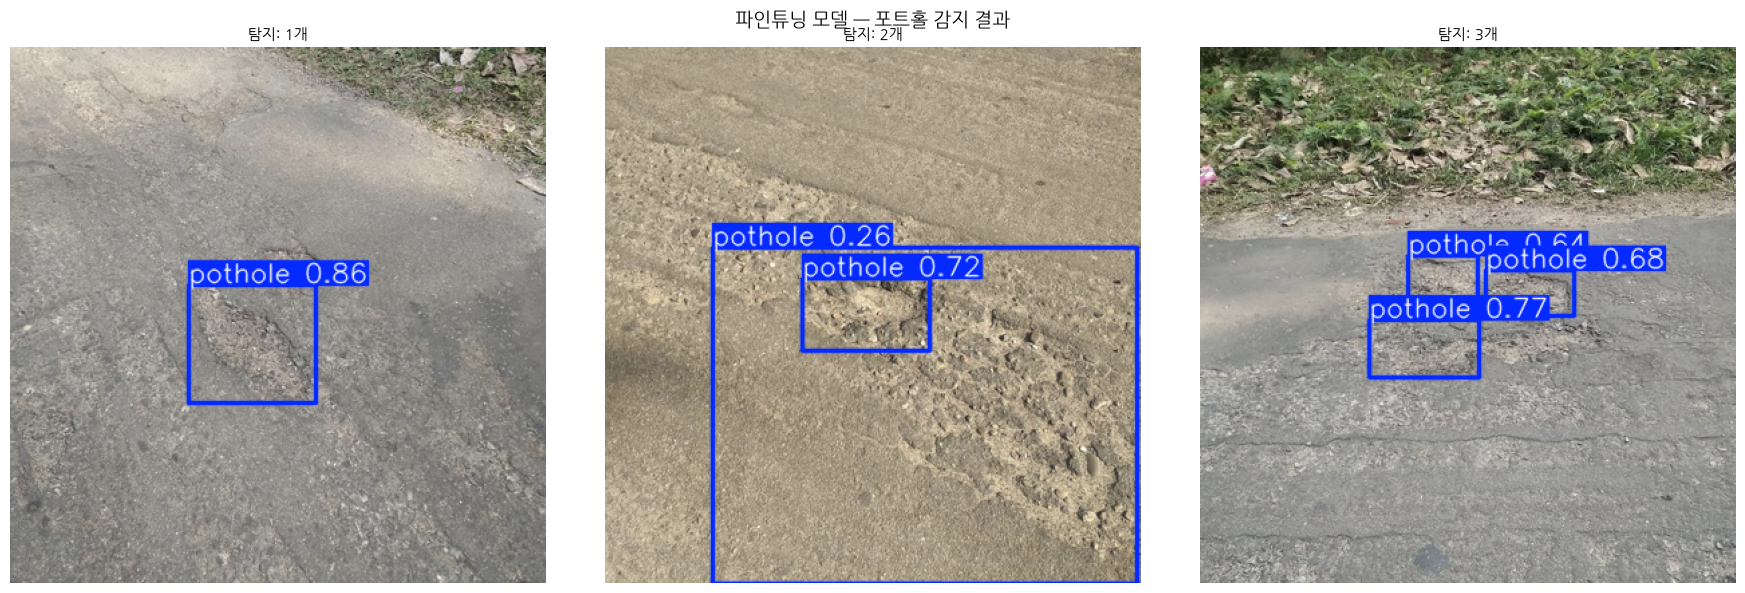

In [15]:
import random
from ultralytics import YOLO
from pathlib import Path
import matplotlib.pyplot as plt
import koreanize_matplotlib

model_ft = YOLO(str(Path(SAVE_DIR) / "weights" / "best.pt"))
print("파인튜닝 모델 클래스:", model_ft.names)

val_dir = Path(DATASET_PATH) / "valid" / "images"
val_images = sorted(list(val_dir.glob("*.jpg")) + list(val_dir.glob("*.png")))
sample_imgs = random.sample(val_images, min(3, len(val_images)))

fig, axes = plt.subplots(1, len(sample_imgs), figsize=(18, 6))
for ax, img_path in zip(axes, sample_imgs):
    result = model_ft(str(img_path), verbose=False)[0]
    ax.imshow(result.plot()[..., ::-1])
    ax.set_title(f"탐지: {len(result.boxes)}개", fontsize=11)
    ax.axis("off")

plt.suptitle("파인튜닝 모델 — 포트홀 감지 결과", fontsize=14)
plt.tight_layout()
plt.show()

## 4.11 정리

- **파인튜닝**은 사전 학습 모델에 내 도메인 데이터를 추가 학습하는 가장 실용적인 방법입니다
- **Kaggle**에서 수십만 개의 공개 데이터셋을 무료로 다운로드할 수 있습니다
- Pascal VOC(XML) 형식의 데이터는 **VOC → YOLO 변환** 후 사용합니다
- YOLO 데이터셋 구조: `images/` + `labels/` 폴더 + `data.yaml` 설정 파일
- 기본 모델에 없는 클래스(안전모)를 파인튜닝 후 감지할 수 있게 됩니다
- **mAP50 > 0.70** 이면 실용적인 성능, **> 0.85** 이면 우수한 성능